<a href="https://colab.research.google.com/github/Oryx-00/mnist-machine-learning/blob/main/mnist_multiclass_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multiclass Classification on the MNIST Dataset

## 1. Data Loading & Exploration
We start by importing the `mnist_784` dataset, which contains 70,000 grayscale images of handwritten digits.

In [14]:
from sklearn.datasets import fetch_openml
mnist=fetch_openml("mnist_784", as_frame=False)

As usual, we explore the dataset by inspecting its features (`X`), target labels (`y`), and their respective shapes ($28 \times 28 = 784$ pixels per image), as well as visualizing a sample digit.

In [15]:
X, y = mnist.data, mnist.target
X, X[0].shape

(array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784)),
 (784,))

In [16]:
y, y.shape

(array(['5', '0', '4', ..., '4', '5', '6'], shape=(70000,), dtype=object),
 (70000,))

(None, '5')

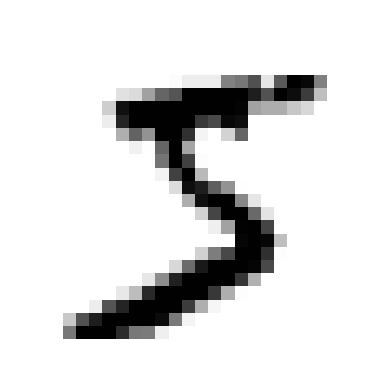

In [17]:
import matplotlib.pyplot as plt

def plot_digit(image_data):
  image = image_data.reshape(28,28)
  plt.imshow(image, cmap="binary")
  plt.axis("off")

some_digit =X[0]
plot_digit(some_digit), y[0]

## 2. Train / Test Split
We split the dataset into a training set (first 60,000 images) and a test set (last 10,000 images). Stratified sampling is not strictly necessary here because the dataset is large enough for the law of large numbers to ensure a balanced class distribution.

In [18]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

## 3. Model Selection & Comparison
We standardize the training features (`X_train`) using `StandardScaler`, which is essential for distance- and gradient-based algorithms like **SVM** and **SGD**. We then define three classifiers to compare: `SVC`, `SGDClassifier`, and `RandomForestClassifier`.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train.astype("float64"))

models = {
  "SVM": SVC(random_state=42),
  "SGD": SGDClassifier(random_state=42),
  "RandomForest": RandomForestClassifier(random_state=42)}

We evaluate the three models using 3-fold cross-validation on a subset of 10,000 images (1/6 of the training set) to keep computation time reasonable, especially for SVM.

In [20]:
for name, model in models.items():
  scores = cross_val_score(model, X_train_scaled[:10000], y_train[:10000], cv=3, scoring="accuracy")
  print(f'Name : {name}, score : {scores.mean():.4f}')

Name : SVM, score : 0.9294


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Name : SGD, score : 0.8967
Name : RandomForest, score : 0.9414


## 4. Training & Error Analysis of the Best Model
While all three models perform well, **Random Forest** achieves the highest cross-validation accuracy (`94.14%`). We select it as our best model and generate out-of-fold predictions across the entire training set (60,000 images).

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict

best_model = RandomForestClassifier(random_state=42)
y_train_pred = cross_val_predict(best_model, X_train_scaled, y_train, cv=3)

We plot the confusion matrix to analyze where the model makes mistakes across the 10 digit classes.

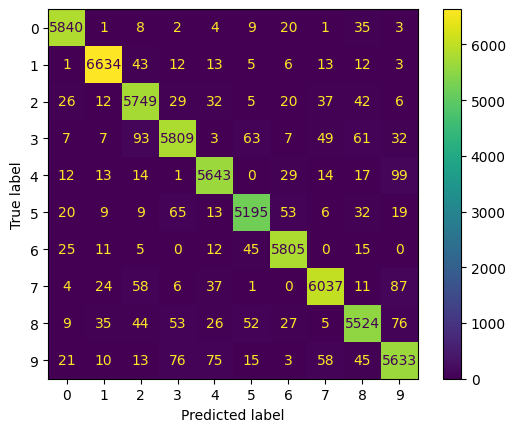

In [22]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred
)
plt.show()

**Observation:** Most predictions fall cleanly along the diagonal. However, the algorithm struggles slightly to differentiate visually similar digits—most notably confusing **4s with 9s** (and vice versa), **7s with 9s**, and **3s with 5s**.

## 5. Final Evaluation on the Test Set
Now that our model is selected and analyzed, we apply the same scaling transformation to the **test set** (`X_test`), fit the Random Forest on the full training set, and generate final predictions.

In [23]:
X_test_scaled = scalar.transform(X_test.astype("float64"))
best_model.fit(X_train_scaled, y_train)

y_test_pred = best_model.predict(X_test_scaled)

We compute the classification report to evaluate precision, recall, and F1-score for each digit on unseen data.

In [24]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.96      0.97      0.97      1032
           3       0.96      0.96      0.96      1010
           4       0.97      0.97      0.97       982
           5       0.98      0.96      0.97       892
           6       0.98      0.98      0.98       958
           7       0.97      0.96      0.97      1028
           8       0.96      0.95      0.96       974
           9       0.96      0.95      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



**Conclusion:** The Random Forest classifier achieves an overall accuracy of **97%** on the 10,000 test images. Performance is remarkably consistent across all classes: the digit **1** is the easiest to recognize (F1-score of **0.99**), while the most challenging digits (**3**, **8**, and **9**) still maintain a strong F1-score of **0.96**.